Name: Nilav Ghosh
Assignment: HW3

Assignment Statement:

After evaluating the data we deduced that the dataset is large, it has missing values, it is biased and has a large number of features, large number of observations and have unbalanced class. So we decided to work with models which scale well, handle non linear relationships, and can account for class imbalance. So the model order we followed:

Logistic regression (Different Permutations)- Nilav

XGBoost (Regular, Improved, Optimized, Deature Selected, SHAP)- Nilav

Naive Bayes - Nilav

Catbooster-Nilav

LightGBM-Nilav

Ensemble (XGBoost+CatBoost+LightGBM)-Nilav


Ada_boost - Ayoola

Neural Networks - Ayoola

Random Trees - Ayoola

Gradient boosting - Ayoola

Extra trees




This notebook contains Nilav's experiments.

In [7]:
#Importing necessary libraries
import pandas as pd
import numpy as np

from sklearn.model_selection import cross_val_score
from sklearn.metrics import accuracy_score
from sklearn.metrics import f1_score
from sklearn.metrics import roc_curve, auc 

from sklearn.model_selection import GridSearchCV

from sklearn.model_selection import train_test_split

import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
%matplotlib inline

from numpy import loadtxt
import xgboost as xgb

from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC

# Going to use these 5 base models for the stacking
from sklearn.ensemble import (RandomForestClassifier, AdaBoostClassifier, 
                              GradientBoostingClassifier, ExtraTreesClassifier)
from sklearn.model_selection import KFold

from sklearn.naive_bayes import GaussianNB

import lightgbm as lgb
from sklearn.metrics import mean_squared_error

import matplotlib as mpl
from matplotlib import colors
from scipy import linalg
from sklearn import datasets
from sklearn.decomposition import PCA
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis

from sklearn.model_selection import train_test_split, learning_curve
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)

In [9]:
!kaggle --version

Kaggle CLI 2.2.4


In [10]:
import pandas as pd

train = pd.read_csv('./train_data.csv')
test = pd.read_csv('./test_data.csv')

train.output.value_counts()  

output
1    3873
0     711
Name: count, dtype: int64

In [11]:
# Read and load the training and test data
train = pd.read_csv("train_data.csv")
test = pd.read_csv("test_data.csv")

try:
    sample_solution = pd.read_csv("sample_solution.csv")
except:
    sample_solution = None

print("Train shape:", train.shape)
print("Test shape :", test.shape)

display(train.head())

Train shape: (4584, 670)
Test shape : (1732, 669)


,x1,x2,x3,x4,x5,x6,x7,x8,x9,x10,...,z217,z218,z219,z220,z221,z222,subject,phase,state,output
0,0,0,0,1,-323.106605,2.694366,-1.987520,261.092784,0.013704,0.000100,...,-0.004930,-0.005554,5.246375,-7.534092,3.530736,-0.539045,K,3,C,1
1,0,0,0,1,-376.084691,0.969696,-6.933765,355.311648,0.030292,-0.000153,...,0.022757,0.052506,-3.727741,-2.854443,-0.699268,-0.054074,A,4,C,1
2,0,0,0,0,91.955425,2.621643,-2.581162,51.357206,0.036668,-0.000104,...,-0.086813,-0.101497,-7.510594,19.564182,-17.008130,4.945392,D,3,C,1
3,0,0,0,1,-391.814586,1.866914,-2.510799,382.900317,0.007947,-0.000028,...,0.030856,-0.161398,-6.435819,2.174453,-0.153956,-0.003958,G,2,C,0
4,0,0,0,0,-363.823732,2.951346,-3.726368,330.527539,0.010074,-0.000004,...,-0.017226,-0.016454,-2.581403,3.011932,-1.281361,0.192647,C,2,C,1


In [12]:
# Training Data information
train.info()

<class 'pandas.DataFrame'>
RangeIndex: 4584 entries, 0 to 4583
Columns: 670 entries, x1 to output
dtypes: float64(474), int64(194), str(2)
memory usage: 23.4 MB


In [13]:
# Identify numerical and categorical columns

print("\nColumns:")
print(train.columns.tolist())

# Missing values:
print("\nMissing values:")
display(train.isnull().sum().sort_values(ascending=False).head(20))

# Unique values
print("\nUnique values:")
display(train.nunique().sort_values())


Columns:
['x1', 'x2', 'x3', 'x4', 'x5', 'x6', 'x7', 'x8', 'x9', 'x10', 'x11', 'x12', 'x13', 'x14', 'x15', 'x16', 'x17', 'x18', 'x19', 'x20', 'x21', 'x22', 'x23', 'x24', 'x25', 'x26', 'x27', 'x28', 'x29', 'x30', 'x31', 'x32', 'x33', 'x34', 'x35', 'x36', 'x37', 'x38', 'x39', 'x40', 'x41', 'x42', 'x43', 'x44', 'x45', 'x46', 'x47', 'x48', 'x49', 'x50', 'x51', 'x52', 'x53', 'x54', 'x55', 'x56', 'x57', 'x58', 'x59', 'x60', 'x61', 'x62', 'x63', 'x64', 'x65', 'x66', 'x67', 'x68', 'x69', 'x70', 'x71', 'x72', 'x73', 'x74', 'x75', 'x76', 'x77', 'x78', 'x79', 'x80', 'x81', 'x82', 'x83', 'x84', 'x85', 'x86', 'x87', 'x88', 'x89', 'x90', 'x91', 'x92', 'x93', 'x94', 'x95', 'x96', 'x97', 'x98', 'x99', 'x100', 'x101', 'x102', 'x103', 'x104', 'x105', 'x106', 'x107', 'x108', 'x109', 'x110', 'x111', 'x112', 'x113', 'x114', 'x115', 'x116', 'x117', 'x118', 'x119', 'x120', 'x121', 'x122', 'x123', 'x124', 'x125', 'x126', 'x127', 'x128', 'x129', 'x130', 'x131', 'x132', 'x133', 'x134', 'x135', 'x136', 'x137', '

x1      0
y219    0
y221    0
y222    0
z1      0
z2      0
z3      0
z4      0
z5      0
z6      0
z7      0
z8      0
z9      0
z10     0
z11     0
z12     0
z13     0
z14     0
z15     0
y220    0
dtype: int64


Unique values:


x1         1
y57        1
y72        1
y73        1
y74        1
        ... 
y60     4584
y61     4584
y62     4584
y19     4584
y161    4584
Length: 670, dtype: int64

Class distribution:
output
1    3873
0     711
Name: count, dtype: int64

Class percentages:
output
1    84.489529
0    15.510471
Name: proportion, dtype: float64


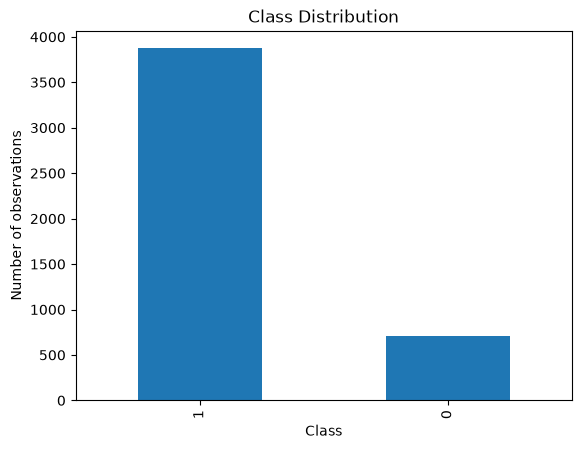

In [14]:
##Checking the class distribution and imbalance in the training data

print("Class distribution:")
print(train['output'].value_counts())

print("\nClass percentages:")
print(train['output'].value_counts(normalize=True) * 100)

train['output'].value_counts().plot(
    kind='bar',
    title='Class Distribution'
)

plt.xlabel("Class")
plt.ylabel("Number of observations")
plt.show()

In [15]:
# Separate features and target of the training data
X = train.drop(columns=['output'])
y = train['output']

# Stratified train-validation split
X_train, X_val, y_train, y_val = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training observations:", X_train.shape)
print("Validation observations:", X_val.shape)

Training observations: (3667, 669)
Validation observations: (917, 669)


In [16]:
# Identify numerical and categorical columns
from sklearn.compose import ColumnTransformer

numeric_features = X.select_dtypes(
    include=['int64', 'float64']
).columns.tolist()

categorical_features = X.select_dtypes(
    include=['object', 'category', 'bool']
).columns.tolist()


# Numeric preprocessing
numeric_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])


# Categorical preprocessing
categorical_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

# Combine preprocessing
preprocessor = ColumnTransformer([
    ('num', numeric_transformer, numeric_features),
    ('cat', categorical_transformer, categorical_features)
])

/var/folders/c3/1xdc_j3d5gnbhhnvrtwj5c540000gn/T/ipykernel_2596/3195068650.py:8: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = X.select_dtypes(


In [2]:
###### Baseline Model ######

##Before developing sophisticated models, we want to understand the class distribution and establish a baseline accuracy. 
##A majority-class classifier provides the minimum accuracy that any meaningful model should outperform.

In [ ]:
#Code generate with the help of AI

baseline_model = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', DummyClassifier(strategy='most_frequent'))
])

baseline_model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](669,)","['x1','x2','x3',...,'subject','phase','state']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,669
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns 

In [ ]:
## Baseline Model Evaluation
#Code generate with the help of AI

# Predictions
baseline_pred = baseline_model.predict(X_val)

# Evaluation
baseline_accuracy = accuracy_score(y_val, baseline_pred)
baseline_precision = precision_score(
    y_val, baseline_pred, zero_division=0
)
baseline_recall = recall_score(
    y_val, baseline_pred, zero_division=0
)
baseline_f1 = f1_score(
    y_val, baseline_pred, zero_division=0
)

print("BASELINE MODEL PERFORMANCE")
print("--------------------------")
print(f"Accuracy : {baseline_accuracy:.4f}")
print(f"Precision: {baseline_precision:.4f}")
print(f"Recall   : {baseline_recall:.4f}")
print(f"F1 Score : {baseline_f1:.4f}")

print("\nClassification Report:")
print(classification_report(y_val, baseline_pred, zero_division=0))

BASELINE MODEL PERFORMANCE
--------------------------
Accuracy : 0.8451
Precision: 0.8451
Recall   : 1.0000
F1 Score : 0.9161

Classification Report:
              precision    recall  f1-score   support

           0       0.00      0.00      0.00       142
           1       0.85      1.00      0.92       775

    accuracy                           0.85       917
   macro avg       0.42      0.50      0.46       917
weighted avg       0.71      0.85      0.77       917



In [ ]:
###### Logistic Regression Model #####

##Next to baseline model, we will implement a logistic regression model. 
#Logistic regression is a simple yet effective linear model for binary classification tasks. 
#It estimates the probability of a binary outcome based on one or more predictor variables.
#It also tells if the problem is linearlyt separable


In [14]:
##Training a Logistic Regression model with class weights to handle class imbalance

logistic_model = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(
        max_iter=2000,
        class_weight='balanced',
        solver='lbfgs',
        C=1.0,
        random_state=42
    ))
])

In [15]:
# Fit the logistic regression model

logistic_model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](669,)","['x1','x2','x3',...,'subject','phase','state']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,669
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns 

In [ ]:
## Model Evaluation for Logistic Regression
#Code generate with the help of AI

# Predictions for Logistic Regression model
logistic_pred = logistic_model.predict(X_val)

# Predicted probabilities for positive class
logistic_prob = logistic_model.predict_proba(X_val)[:, 1]

# Metrics
logistic_accuracy = accuracy_score(y_val, logistic_pred)

logistic_precision = precision_score(
    y_val, logistic_pred, zero_division=0
)

logistic_recall = recall_score(
    y_val, logistic_pred, zero_division=0
) 

logistic_f1 = f1_score(
    y_val, logistic_pred, zero_division=0
)

logistic_auc = roc_auc_score(y_val, logistic_prob)

print("LOGISTIC REGRESSION PERFORMANCE")
print("-------------------------------")
print(f"Accuracy : {logistic_accuracy:.4f}")
print(f"Precision: {logistic_precision:.4f}")
print(f"Recall   : {logistic_recall:.4f}")
print(f"F1 Score : {logistic_f1:.4f}")
print(f"ROC-AUC  : {logistic_auc:.4f}")

print("\nClassification Report:")
print(classification_report(y_val, logistic_pred))

LOGISTIC REGRESSION PERFORMANCE
-------------------------------
Accuracy : 0.7328
Precision: 0.9288
Recall   : 0.7406
F1 Score : 0.8241
ROC-AUC  : 0.7908

Classification Report:
              precision    recall  f1-score   support

           0       0.33      0.69      0.44       142
           1       0.93      0.74      0.82       775

    accuracy                           0.73       917
   macro avg       0.63      0.72      0.63       917
weighted avg       0.84      0.73      0.77       917



In [17]:
## Model Comparison between Baseline and Logistic Regression

comparison = pd.DataFrame({
    'Model': [
        'Baseline',
        'Logistic Regression'
    ],
    'Accuracy': [
        baseline_accuracy,
        logistic_accuracy
    ],
    'Precision': [
        baseline_precision,
        logistic_precision
    ],
    'Recall': [
        baseline_recall,
        logistic_recall
    ],
    'F1 Score': [
        baseline_f1,
        logistic_f1
    ]
})

display(comparison)

,Model,Accuracy,Precision,Recall,F1 Score
0,Baseline,0.845147,0.845147,1.000000,0.916076
1,Logistic Regression,0.732824,0.928803,0.740645,0.824121


In [ ]:
#Train Logistic Regression on the entire training dataset
#Code generated with the help of AI

X_full = train.drop(columns=['output'])
y_full = train['output']

logistic_model.fit(X_full, y_full)

# Predict probabilities for the Kaggle test dataset
preds = logistic_model.predict_proba(test)

# Create submission DataFrame
submithis = pd.DataFrame([
    test.index,
    preds[:, 1]
]).T

submithis.columns = ['id', 'output']
submithis.id = submithis.id.astype(int)

display(submithis.head())

# Save submission
submithis.to_csv('submission_logistic.csv', index=False)

print("Submission file created successfully!")

,id,output
0,0,0.161697
1,1,0.960852
2,2,0.536888
3,3,0.661943
4,4,0.675553


Submission file created successfully!


In [19]:
##Generate learning curves for the logistic regression model
from sklearn.model_selection import StratifiedKFold

# Stratified cross-validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Training dataset sizes
train_sizes = np.linspace(0.1, 1.0, 8)

# Calculate learning curves
train_sizes_abs, train_scores, val_scores = learning_curve(
    estimator=logistic_model,
    X=X_train,
    y=y_train,
    train_sizes=train_sizes,
    cv=cv,
    scoring='f1',
    n_jobs=-1,
    shuffle=True,
    random_state=42
)

# Mean scores
train_mean = np.mean(train_scores, axis=1)
val_mean = np.mean(val_scores, axis=1)

# Standard deviations
train_std = np.std(train_scores, axis=1)
val_std = np.std(val_scores, axis=1)

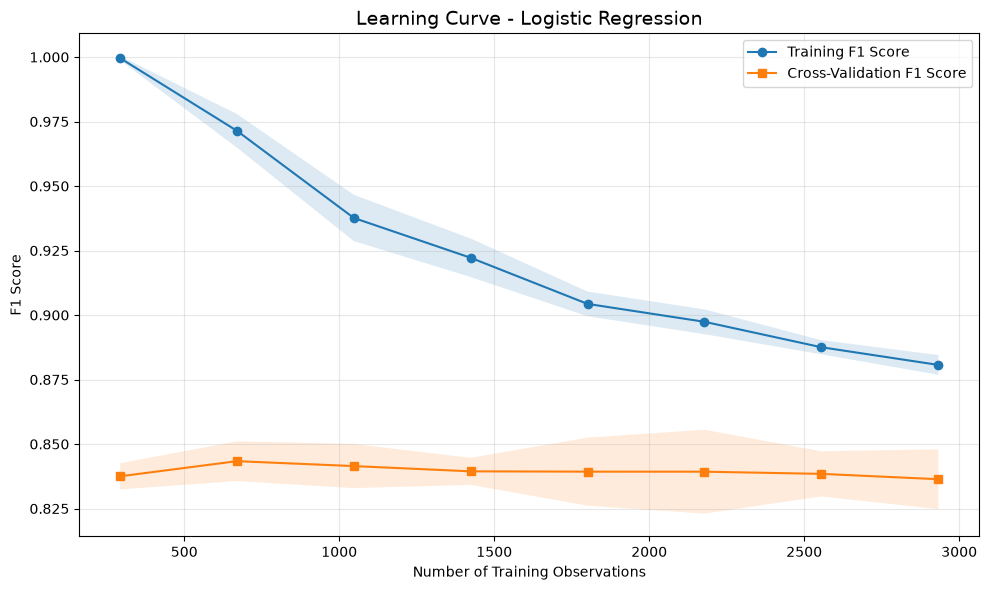

In [20]:
##Generate learning curve plot

plt.figure(figsize=(10, 6))

# Training curve
plt.plot(
    train_sizes_abs,
    train_mean,
    marker='o',
    label='Training F1 Score'
)

# Validation curve
plt.plot(
    train_sizes_abs,
    val_mean,
    marker='s',
    label='Cross-Validation F1 Score'
)

# Training variance
plt.fill_between(
    train_sizes_abs,
    train_mean - train_std,
    train_mean + train_std,
    alpha=0.15
)

# Validation variance
plt.fill_between(
    train_sizes_abs,
    val_mean - val_std,
    val_mean + val_std,
    alpha=0.15
)

plt.title(
    'Learning Curve - Logistic Regression',
    fontsize=14
)

plt.xlabel('Number of Training Observations')
plt.ylabel('F1 Score')

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.show()

In [ ]:
#Code generated with the help of AI

def diagnose_model(
    train_scores,
    val_scores,
    gap_threshold=0.10,
    low_score_threshold=0.60
):

    train_f1 = np.mean(train_scores[-3:])
    val_f1 = np.mean(val_scores[-3:])

    gap = train_f1 - val_f1

    print("MODEL DIAGNOSTICS")
    print("------------------------------")
    print(f"Training F1   : {train_f1:.4f}")
    print(f"Validation F1 : {val_f1:.4f}")
    print(f"Gap           : {gap:.4f}")

    if gap > gap_threshold:

        print("\nDiagnosis: Possible OVERFITTING")
        print("Training performance is considerably higher.")
        print("Consider stronger regularization or more data.")

    elif (
        train_f1 < low_score_threshold
        and val_f1 < low_score_threshold
    ):

        print("\nDiagnosis: Possible UNDERFITTING")
        print("Both training and validation scores are low.")
        print("Consider feature engineering or a more flexible model.")

    else:

        print("\nDiagnosis: No obvious severe overfitting.")
        print("Assess performance against your baseline.")

In [22]:
diagnose_model(
    train_mean,
    val_mean
)

MODEL DIAGNOSTICS
------------------------------
Training F1   : 0.8885
Validation F1 : 0.8380
Gap           : 0.0505

Diagnosis: No obvious severe overfitting.
Assess performance against your baseline.


##### Improvement: Feature Selection using Logistic Regression with L1 regularization #####



In [ ]:
#Improvement: Feature Selection using Logistic Regression with L1 regularization
#This improvement aims to enhance the model's performance by selecting the most relevant features using L1 regularization.

from sklearn.feature_selection import SelectFromModel

feature_selection_lr = Pipeline([
    ('preprocessor', preprocessor),

    ('feature_selection', SelectFromModel(
        LogisticRegression(
            penalty='l1',
            solver='liblinear',
            C=0.1,
            max_iter=3000
        )
    )),

    ('classifier', LogisticRegression(
        C=1.0,
        max_iter=3000,
        class_weight='balanced',
        random_state=42
    ))
])

feature_selection_lr.fit(X_train, y_train)

preds = feature_selection_lr.predict_proba(X_val)[:, 1]

print(
    "Feature Selection ROC-AUC:",
    roc_auc_score(y_val, preds)
)

/opt/miniconda3/envs/section_5/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/opt/miniconda3/envs/section_5/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1407: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(


Feature Selection ROC-AUC: 0.8124307133121309


In [14]:
# Train Logistic Regression with Feature Selection
# using the complete labeled training dataset

feature_selection_lr.fit(X, y)

/opt/miniconda3/envs/section_5/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/opt/miniconda3/envs/section_5/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1407: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('feature_selection', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](669,)","['x1','x2','x3',...,'subject','phase','state']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,669
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remain

In [ ]:
#Code generated with the help of AI

# Prepare test features
test_1 = test.reindex(columns=X.columns)

# Generate predicted probabilities
preds = feature_selection_lr.predict_proba(test_1)

# Create submission DataFrame
submithis = pd.DataFrame([test_1.index, preds[:, 1]]).T
submithis.columns = ['id', 'output']
submithis.id = submithis.id.astype(int)

# Display submission
submithis

,id,output
0,0,0.359823
1,1,0.840429
2,2,0.520054
3,3,0.520288
4,4,0.746260
...,...,...
1727,1727,0.700496
1728,1728,0.618997
1729,1729,0.567410
1730,1730,0.804203


In [ ]:
# Save the submission file for the Logistic Regression model with Feature Selection

submithis.to_csv('submission_feature_selection.csv', index=False)

In [42]:
##Improved Logistic Regression with Hyperparameter Optimization

In [17]:
##Improved Logistic Regression Pipeline with Hyperparameter Optimization


##Improvements:
##L1 feature selection to remove less useful features.
##Elastic Net regularization to balance feature sparsity and coefficient stability.
##Hyperparameter tuning using stratified cross-validation.
##ROC-AUC optimization rather than accuracy.
##Tests different class-weight configurations.
##Automatically selects the best combination of parameters.

from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.feature_selection import SelectFromModel
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold
from sklearn.metrics import roc_auc_score
from scipy.stats import loguniform

# Faster Logistic Regression
fast_lr = Pipeline([

    ('preprocessor', preprocessor),

    ('feature_selection', SelectFromModel(
        LogisticRegression(
            penalty='l1',
            solver='liblinear',
            C=0.1,
            max_iter=1000,
            random_state=42
        )
    )),

    ('classifier', LogisticRegression(
        penalty='l2',
        solver='liblinear',
        max_iter=1000,
        random_state=42
    ))
])

# Smaller hyperparameter space
param_dist = {

    'feature_selection__estimator__C': [
        0.01, 0.1, 1.0
    ],

    'classifier__C': [
        0.01, 0.1, 1.0, 10
    ],

    'classifier__class_weight': [
        None, 'balanced'
    ]
}

# 3-fold cross-validation
cv = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

# Faster search
lr_search = RandomizedSearchCV(
    estimator=fast_lr,
    param_distributions=param_dist,
    n_iter=10,
    scoring='roc_auc',
    cv=cv,
    n_jobs=2,
    verbose=1,
    random_state=42
)

# Train
lr_search.fit(X_train, y_train)

# Best model
best_lr = lr_search.best_estimator_

# Predictions
lr_probs = best_lr.predict_proba(X_val)[:, 1]

print("Best Parameters:", lr_search.best_params_)

print("Best CV ROC-AUC:", lr_search.best_score_)

print(
    "Validation ROC-AUC:",
    roc_auc_score(y_val, lr_probs)
)

Fitting 3 folds for each of 10 candidates, totalling 30 fits


/opt/miniconda3/envs/section_5/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/opt/miniconda3/envs/section_5/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1407: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(
/opt/miniconda3/envs/section_5/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. 

Best Parameters: {'feature_selection__estimator__C': 0.1, 'classifier__class_weight': 'balanced', 'classifier__C': 1.0}
Best CV ROC-AUC: 0.7904314889238165
Validation ROC-AUC: 0.8124034529759201


/opt/miniconda3/envs/section_5/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(


In [18]:
##Evaluate how many features were selected by the feature selection step in the improved logistic regression pipeline

# Retrieve fitted feature selector
selector = best_lr.named_steps['feature_selection']

# Retrieve feature names after preprocessing
feature_names = best_lr.named_steps[
    'preprocessor'
].get_feature_names_out()

# Identify selected features
selected_mask = selector.get_support()

selected_features = feature_names[selected_mask]

print("Total Features:", len(feature_names))

print("Selected Features:", len(selected_features))

print("Removed Features:", len(feature_names) - len(selected_features))

Total Features: 683
Selected Features: 118
Removed Features: 565


            Feature  Coefficient  Importance
114  cat__subject_K     3.911539    3.911539
112  cat__subject_G    -2.170483    2.170483
108  cat__subject_A     1.432577    1.432577
116  cat__subject_M    -1.285749    1.285749
111  cat__subject_F    -0.882752    0.882752
109  cat__subject_C    -0.851302    0.851302
113  cat__subject_I     0.786729    0.786729
61        num__y203     0.694713    0.694713
86         num__z78     0.691326    0.691326
115  cat__subject_L     0.686760    0.686760
110  cat__subject_D     0.655168    0.655168
87         num__z83     0.539739    0.539739
80         num__z58     0.533655    0.533655
2           num__x8    -0.460499    0.460499
46         num__y83    -0.420472    0.420472
10         num__x76    -0.383717    0.383717
78         num__z50    -0.379353    0.379353
43         num__y69     0.356056    0.356056
41         num__y58     0.341020    0.341020
57        num__y156     0.316906    0.316906


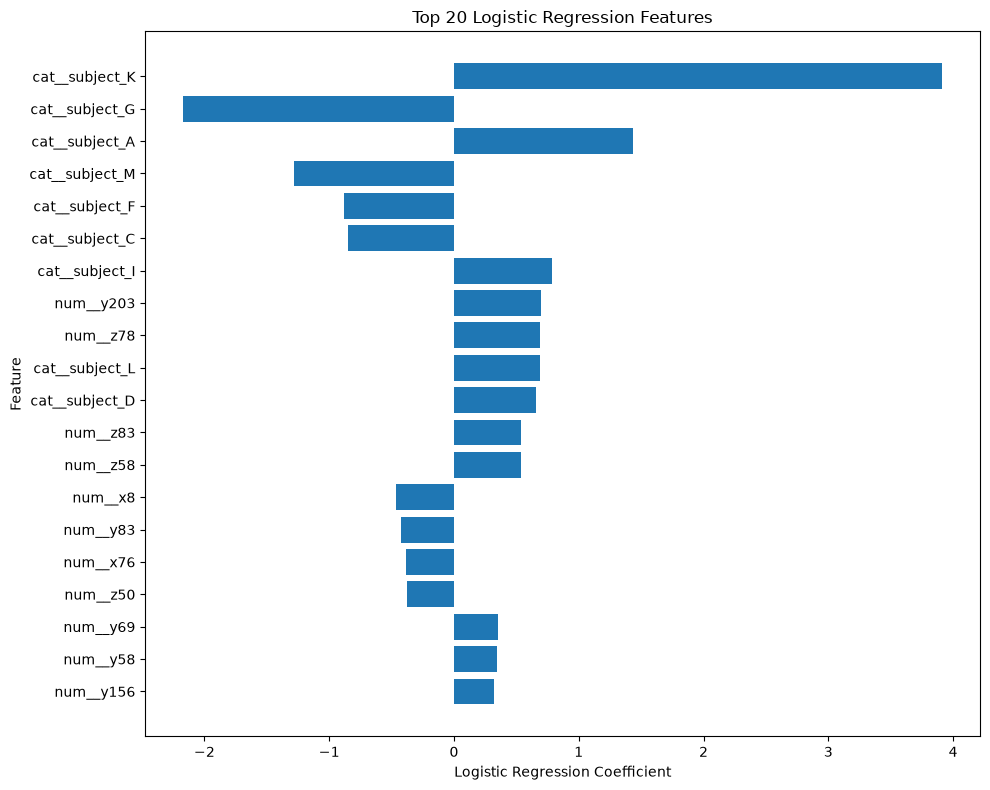

In [19]:
##Visualize the top 20 features based on their coefficients in the improved logistic regression model

import pandas as pd
import matplotlib.pyplot as plt

# Extract coefficients
coefficients = best_lr.named_steps[
    'classifier'
].coef_[0]

# Create importance dataframe
importance_df = pd.DataFrame({
    'Feature': selected_features,
    'Coefficient': coefficients,
    'Importance': np.abs(coefficients)
})

# Sort by absolute importance
importance_df = importance_df.sort_values(
    by='Importance',
    ascending=False
)

print(importance_df.head(20))

# Plot top 20 features
plt.figure(figsize=(10, 8))

top_features = importance_df.head(20).iloc[::-1]

plt.barh(
    top_features['Feature'],
    top_features['Coefficient']
)

plt.xlabel("Logistic Regression Coefficient")
plt.ylabel("Feature")
plt.title("Top 20 Logistic Regression Features")

plt.tight_layout()
plt.show()

In [ ]:
# Load sample solution
#Code generated with the help of AI

sample_solution = pd.read_csv(
    "sample_solution.csv"
)

# Prepare test data
test_1 = test.reindex(columns=X_train.columns)

# Generate predictions
test_probs = best_lr.predict_proba(test_1)[:, 1]

# Create submission
submission = sample_solution.copy()

submission["output"] = test_probs

# Save submission file
submission.to_csv(
    "logistic_regression_optimized_submission.csv",
    index=False
)

print(submission.head())

print("Submission shape:", submission.shape)

   id    output
0   0  0.327589
1   1  0.711085
2   2  0.564783
3   3  0.511049
4   4  0.745510
Submission shape: (1732, 2)


In [18]:
##### XGBoost Classifier ########

###XGBoost is a powerful gradient boosting algorithm that is widely used for structured/tabular data.
##This model is particularly effective for handling complex relationships and interactions between features, making it a strong choice for many classification tasks.



We use XGBoost because the dataset contains many features, nonlinear relationships, missing values, and substantial class imbalance, XGBoost may outperform simpler models. Gradient boosting allows each successive tree to focus on errors from previous trees, while regularization, feature subsampling, row subsampling, and class weighting can help reduce overfitting and address imbalance. XGBoost also provides feature importance and integrates well with SHAP, making it suitable for both predictive performance and model explainability.

In [17]:
#Code generated with the help of AI

from xgboost import XGBClassifier

# Calculate class imbalance ratio
class_counts = y_train.value_counts()

scale_pos_weight = (
    class_counts[0] / class_counts[1]
)

print("Scale Positive Weight:", scale_pos_weight)

xgb_model = Pipeline([
    ('preprocessor', preprocessor),

    ('classifier', XGBClassifier(
        n_estimators=500,
        max_depth=4,
        learning_rate=0.03,
        subsample=0.8,
        colsample_bytree=0.8,
        objective='binary:logistic',
        eval_metric='auc',
        random_state=42,
        n_jobs=2
    ))
])

xgb_model.fit(X_train, y_train)

xgb_preds = xgb_model.predict_proba(X_val)[:, 1]

print(
    "XGBoost Validation ROC-AUC:",
    roc_auc_score(y_val, xgb_preds)
)

Scale Positive Weight: 0.18366688185926405
XGBoost Validation ROC-AUC: 0.859418446160836


In [ ]:
# Prepare test data
test_1 = test.reindex(columns=X.columns)

# Generate predicted probabilities
preds = xgb_model.predict_proba(test_1)

# Create submission DataFrame
submithis = pd.DataFrame([test_1.index, preds[:, 1]]).T

submithis.columns = ['id', 'output']

submithis.id = submithis.id.astype(int)

# Display submission
submithis

,id,output
0,0,0.890614
1,1,0.954558
2,2,0.932373
3,3,0.762751
4,4,0.834526
...,...,...
1727,1727,0.932693
1728,1728,0.949144
1729,1729,0.936582
1730,1730,0.940488


In [23]:
# Save submission file
submithis.to_csv(
    'submission_xgboost.csv',
    index=False
)

In [44]:
######Improved XGBoost Classifier with Hyperparameter Optimization, early stopping and feature selection ######

In [ ]:
#Code generated with the help of AI

import numpy as np
import pandas as pd

from sklearn.base import clone
from sklearn.metrics import roc_auc_score
from xgboost import XGBClassifier


# Calculate class imbalance
class_counts = y_train.value_counts()

scale_pos_weight = (
    class_counts[0] / class_counts[1]
)

print("Class distribution:")
print(class_counts)

print("Scale Positive Weight:", scale_pos_weight)



# Preprocess training and validation data
optimized_preprocessor = clone(preprocessor)

X_train_processed = optimized_preprocessor.fit_transform(
    X_train
)

X_val_processed = optimized_preprocessor.transform(
    X_val
)


# Build optimized XGBoost
optimized_xgb = XGBClassifier(

    n_estimators=2000,
    max_depth=3,
    learning_rate=0.025,
    min_child_weight=5,
    subsample=0.85,
    colsample_bytree=0.75,
    gamma=0.1,
    reg_alpha=0.5,
    reg_lambda=5,
    scale_pos_weight=1,
    objective='binary:logistic',
    eval_metric='auc',
    tree_method='hist',
    early_stopping_rounds=75,
    random_state=42,
    n_jobs=2

)

# Train with early stopping
optimized_xgb.fit(

    X_train_processed,
    y_train,
    eval_set=[
        (X_val_processed, y_val)
    ],

    verbose=False
)

# Validate
optimized_preds = optimized_xgb.predict_proba(
    X_val_processed
)[:, 1]

optimized_auc = roc_auc_score(
    y_val,
    optimized_preds
)

print(
    "Optimized XGBoost ROC-AUC:",
    optimized_auc
)

print(
    "Best iteration:",
    optimized_xgb.best_iteration
)

Class distribution:
output
1    3098
0     569
Name: count, dtype: int64
Scale Positive Weight: 0.18366688185926405
Optimized XGBoost ROC-AUC: 0.8509859154929579
Best iteration: 311


In [ ]:
### Feature Selection using the optimized XGBoost model

from sklearn.feature_selection import SelectFromModel
from sklearn.metrics import roc_auc_score

# Feature selection
selector = SelectFromModel(

    optimized_xgb,
    prefit=True,
    threshold=-np.inf,
    max_features=150
)

X_train_selected = selector.transform(
    X_train_processed
)

X_val_selected = selector.transform(
    X_val_processed
)

print(
    "Original number of processed features:",
    X_train_processed.shape[1]
)

print(
    "Selected features:",
    X_train_selected.shape[1]
)


# Train new XGBoost with selected features
selected_xgb = XGBClassifier(

    n_estimators=2000,
    max_depth=3,
    learning_rate=0.025,
    min_child_weight=5,
    subsample=0.85,
    colsample_bytree=0.75,
    gamma=0.1,
    reg_alpha=0.5,
    reg_lambda=5,
    scale_pos_weight=1,
    objective='binary:logistic',
    eval_metric='auc',
    tree_method='hist',
    early_stopping_rounds=75,
    random_state=42,
    n_jobs=2
)


selected_xgb.fit(

    X_train_selected,
    y_train,

    eval_set=[
        (X_val_selected, y_val)
    ],
    verbose=False
)


# Evaluate

selected_preds = selected_xgb.predict_proba(
    X_val_selected
)[:, 1]

selected_auc = roc_auc_score(
    y_val,
    selected_preds
)

print(
    "Feature Selected XGBoost ROC-AUC:",
    selected_auc
)

Original number of processed features: 683
Selected features: 150
Feature Selected XGBoost ROC-AUC: 0.8589186733303044


In [ ]:
### Compare all three models: Original XGBoost, Optimized XGBoost, and Feature Selected XGBoost
#Code generated with the help of AI

results = pd.DataFrame({

    "Model": [
        "Original XGBoost",
        "Optimized XGBoost",
        "Feature Selected XGBoost"
    ],

    "Validation ROC-AUC": [
        roc_auc_score(y_val, xgb_preds),
        optimized_auc,
        selected_auc
    ]

})

results = results.sort_values(
    by="Validation ROC-AUC",
    ascending=False
)

print(results)

                      Model  Validation ROC-AUC
0          Original XGBoost            0.866215
2  Feature Selected XGBoost            0.858919
1         Optimized XGBoost            0.850986


In [ ]:
# Select best model
#Code generated with the help of AI

if selected_auc > optimized_auc:
    best_model = selected_xgb
    print("Using Feature Selected XGBoost")

else:
    best_model = optimized_xgb
    print("Using Optimized XGBoost")


# Prepare test data

test_1 = test.reindex(columns=X.columns)
test_processed = optimized_preprocessor.transform(
    test_1
)


# Apply feature selection if necessary

if best_model is selected_xgb:

    test_processed = selector.transform(
        test_processed
    )


# Generate probabilities
test_probs = best_model.predict_proba(
    test_processed
)[:, 1]


# Load sample solution
sample_solution = pd.read_csv(

    "sample_solution.csv"

)

# Create submission
submission = sample_solution.copy()
submission["output"] = test_probs


# Save submission

submission.to_csv(
    "xgboost_optimized_submission.csv",
    index=False
)


# Verify
print(submission.head())

print(
    "Submission shape:",
    submission.shape
)

print(
    "Missing predictions:",
    submission["output"].isnull().sum()
)

Using Feature Selected XGBoost
   id    output
0   0  0.895186
1   1  0.950224
2   2  0.870076
3   3  0.731898
4   4  0.893090
Submission shape: (1732, 2)
Missing predictions: 0


In [ ]:
##### CatBoost Classifier #####

##We use catboost, a gradient boosting library that handles categorical features natively.
##This model is particularly effective for datasets with categorical variables, as it can automatically process them without the need for one-hot encoding.



In [19]:
import pandas as pd
import numpy as np

from catboost import CatBoostClassifier
from sklearn.metrics import roc_auc_score

#Code generated with the help of AI

# Prepare training and validation data
X_train_cat = X_train.copy()
X_val_cat = X_val.copy()

# Identify categorical columns
cat_features = X_train_cat.select_dtypes(
    include=["object", "category", "string"]
).columns.tolist()

# Convert categorical missing values to strings
for col in cat_features:

    X_train_cat[col] = (
        X_train_cat[col].fillna("Missing").astype(str)
    )

    X_val_cat[col] = (
        X_val_cat[col].fillna("Missing").astype(str)
    )

# Initialize CatBoost
cat_model = CatBoostClassifier(

    iterations=2000,
    depth=5,
    learning_rate=0.025,
    l2_leaf_reg=5,
    loss_function="Logloss",
    eval_metric="AUC",
    random_seed=42,
    early_stopping_rounds=100,
    verbose=False

)

# Train
cat_model.fit(

    X_train_cat,
    y_train,
    cat_features=cat_features,
    eval_set=(X_val_cat, y_val)

)

# Predictions
cat_preds = cat_model.predict_proba(
    X_val_cat
)[:, 1]

# Evaluate
cat_auc = roc_auc_score(
    y_val,
    cat_preds
)

print("CatBoost Validation ROC-AUC:", cat_auc)

print("Best iteration:", cat_model.best_iteration_)

CatBoost Validation ROC-AUC: 0.8673512039981827
Best iteration: 441


In [20]:
# Prepare test data
#Code generated with the help of AI

test_cat = test.reindex(
    columns=X_train_cat.columns
).copy()

for col in cat_features:

    test_cat[col] = (
        test_cat[col].fillna("Missing").astype(str)
    )

# Generate predictions
cat_test_probs = cat_model.predict_proba(
    test_cat
)[:, 1]

# Load sample solution
sample_solution = pd.read_csv(
    "sample_solution.csv"
)

# Create submission
submission = sample_solution.copy()
submission["output"] = cat_test_probs

submission.to_csv(
    "catboost_submission.csv",
    index=False
)

print(submission.head())
print("Submission shape:", submission.shape)

   id    output
0   0  0.613334
1   1  0.951838
2   2  0.832086
3   3  0.785167
4   4  0.616044
Submission shape: (1732, 2)


In [ ]:
##### LightGBM Classifier #####

##LightGBM — particularly strong for large datasets with many rows/features.
##This model is designed to be efficient and scalable, making it suitable for high-dimensional data.

In [ ]:
import lightgbm as lgb

from sklearn.pipeline import Pipeline
from sklearn.metrics import roc_auc_score

#Code generated with the help of AI

lgb_model = Pipeline([

    ("preprocessor", preprocessor),
    ("classifier", lgb.LGBMClassifier(

        n_estimators=700,
        learning_rate=0.025,
        num_leaves=15,
        max_depth=5,
        min_child_samples=30,
        subsample=0.8,
        subsample_freq=1,
        colsample_bytree=0.75,
        reg_alpha=0.5,
        reg_lambda=5,
        objective="binary",
        verbosity=-1,
        random_state=42,
        n_jobs=2

    ))

])

lgb_model.fit(
    X_train,
    y_train
)

lgb_preds = lgb_model.predict_proba(
    X_val
)[:, 1]

lgb_auc = roc_auc_score(
    y_val,
    lgb_preds
)

print(
    "LightGBM Validation ROC-AUC:",
    lgb_auc
)

LightGBM Validation ROC-AUC: 0.8585006815084053


In [ ]:
# Generate probabilities and submission file

test_1 = test.reindex(columns=X.columns)

lgb_test_probs = lgb_model.predict_proba(
    test_1
)[:, 1]

sample_solution = pd.read_csv(
    "sample_solution.csv"
)

submission = sample_solution.copy()

submission["output"] = lgb_test_probs

submission.to_csv(
    "lightgbm_submission.csv",
    index=False
)

print(submission.head())

   id    output
0   0  0.874888
1   1  0.964974
2   2  0.927976
3   3  0.793542
4   4  0.834734


In [ ]:
#### Ensemble Classifier using XGBoost, CatBoost, and LightGBM ####

#This is an ensemble model that combines the predictions of XGBoost, CatBoost, and LightGBM classifiers. 
#The ensemble approach can often yield better performance by leveraging the strengths of each individual model.

In [ ]:
#Code generated with the help of AI

from sklearn.metrics import roc_auc_score

# Ensemble probabilities
ensemble_preds = (

    0.40 * cat_preds +
    0.35 * optimized_preds +
    0.25 * lgb_preds

)

ensemble_auc = roc_auc_score(
    y_val,
    ensemble_preds
)

print(
    "Ensemble Validation ROC-AUC:",
    ensemble_auc
)

Ensemble Validation ROC-AUC: 0.8655247614720583


In [ ]:
# Prepare test dataset
test_1 = test.reindex(columns=X.columns)

# XGBoost probabilities
test_processed = optimized_preprocessor.transform(
    test_1
)

xgb_test_probs = optimized_xgb.predict_proba(
    test_processed
)[:, 1]

# CatBoost probabilities
cat_test_probs = cat_model.predict_proba(
    test_cat
)[:, 1]

# LightGBM probabilities
lgb_test_probs = lgb_model.predict_proba(
    test_1
)[:, 1]

# Ensemble
ensemble_test_probs = (
    
    0.40 * cat_test_probs +
    0.35 * xgb_test_probs +
    0.25 * lgb_test_probs

)

# ensemblesubmission
sample_solution = pd.read_csv(
    "sample_solution.csv"
)

submission = sample_solution.copy()

submission["output"] = ensemble_test_probs

submission.to_csv(
    "ensemble_submission.csv",
    index=False
)

print(submission.head())

print("Submission shape:", submission.shape)

   id    output
0   0  0.780004
1   1  0.945674
2   2  0.860053
3   3  0.767698
4   4  0.765722
Submission shape: (1732, 2)


In [50]:
#### Naive Bayes Classifier ####

##Gaussian Naive Bayes is a simple probabilistic classifier based on applying Bayes' theorem with strong (naive) independence assumptions between the features.
##Optimized Naive Bayes Classifier with hyperparameter tuning and feature selection
##Naive Bayes with feature selection and hyperparameter tuning 

In [ ]:
#Code generated with the help of AI

import pandas as pd
import numpy as np

from sklearn.naive_bayes import GaussianNB

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer
from sklearn.metrics import (
    accuracy_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)

# Create Gaussian Naive Bayes pipeline
nb_model = Pipeline([
    ('preprocessor', preprocessor),

    # Convert sparse matrices to dense if necessary
    ('to_dense', FunctionTransformer(
        lambda x: x.toarray() if hasattr(x, 'toarray') else x
    )),

    ('classifier', GaussianNB())
])

# Train model
nb_model.fit(X_train, y_train)

# Predict classes
nb_predictions = nb_model.predict(X_val)

# Predict probabilities
nb_probs = nb_model.predict_proba(X_val)[:, 1]

# Evaluate
print("Gaussian Naive Bayes Results")
print("----------------------------")

print(
    "Accuracy:",
    accuracy_score(y_val, nb_predictions)
)

print(
    "ROC-AUC:",
    roc_auc_score(y_val, nb_probs)
)

print("\nClassification Report:")
print(classification_report(y_val, nb_predictions))

print("\nConfusion Matrix:")
print(confusion_matrix(y_val, nb_predictions))

Gaussian Naive Bayes Results
----------------------------
Accuracy: 0.4187568157033806
ROC-AUC: 0.652121762835075

Classification Report:
              precision    recall  f1-score   support

           0       0.20      0.92      0.33       142
           1       0.96      0.33      0.49       775

    accuracy                           0.42       917
   macro avg       0.58      0.62      0.41       917
weighted avg       0.84      0.42      0.46       917


Confusion Matrix:
[[131  11]
 [522 253]]


In [37]:
from sklearn.model_selection import GridSearchCV, StratifiedKFold

# Create pipeline
nb_pipeline = Pipeline([
    ('preprocessor', preprocessor),

    ('to_dense', FunctionTransformer(
        lambda x: x.toarray() if hasattr(x, 'toarray') else x
    )),

    ('classifier', GaussianNB())
])

# Hyperparameter grid
param_grid = {
    'classifier__var_smoothing': np.logspace(-12, 0, 25)
}

# Stratified cross-validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Grid search
nb_grid = GridSearchCV(
    estimator=nb_pipeline,
    param_grid=param_grid,
    scoring='roc_auc',
    cv=cv,
    n_jobs=2,
    verbose=1
)

# Train
nb_grid.fit(X_train, y_train)

print("Best Parameters:")
print(nb_grid.best_params_)

print(
    "Best Cross-Validation ROC-AUC:",
    nb_grid.best_score_
)

# Best model
best_nb_model = nb_grid.best_estimator_

# Validation predictions
best_nb_probs = best_nb_model.predict_proba(X_val)[:, 1]

print(
    "Optimized Naive Bayes Validation ROC-AUC:",
    roc_auc_score(y_val, best_nb_probs)
)

Fitting 5 folds for each of 25 candidates, totalling 125 fits
Best Parameters:
{'classifier__var_smoothing': np.float64(1e-09)}
Best Cross-Validation ROC-AUC: 0.6597039982750623
Optimized Naive Bayes Validation ROC-AUC: 0.652121762835075


In [ ]:
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.model_selection import GridSearchCV

# Naive Bayes with feature selection
feature_selection_nb = Pipeline([
    ('preprocessor', preprocessor),

    ('to_dense', FunctionTransformer(
        lambda x: x.toarray() if hasattr(x, 'toarray') else x
    )),

    ('selection', SelectKBest(
        score_func=f_classif,
        k=100
    )),

    ('classifier', GaussianNB())
])

# Parameters
param_grid_fs = {
    'selection__k': [25, 50, 100, 200, 300, 'all'],

    'classifier__var_smoothing': [
        1e-2,
        1e-4,
        1e-6,
        1e-8,
        1e-10
    ]
}

# Grid search
nb_fs_grid = GridSearchCV(
    estimator=feature_selection_nb,
    param_grid=param_grid_fs,
    scoring='roc_auc',
    cv=5,
    n_jobs=2,
    verbose=1
)

# Train
nb_fs_grid.fit(X_train, y_train)

print("Best Parameters:")
print(nb_fs_grid.best_params_)

print(
    "Best Cross-Validation ROC-AUC:",
    nb_fs_grid.best_score_
)

# Best estimator
best_fs_nb = nb_fs_grid.best_estimator_

# Validation probabilities
fs_nb_probs = best_fs_nb.predict_proba(X_val)[:, 1]

print(
    "Feature Selection Naive Bayes ROC-AUC:",
    roc_auc_score(y_val, fs_nb_probs)
)

Fitting 5 folds for each of 30 candidates, totalling 150 fits


/opt/miniconda3/envs/section_5/lib/python3.14/site-packages/sklearn/feature_selection/_univariate_selection.py:110: UserWarning: Features [  0  13  38  47  56  71  72  73  80  85  86  90  91  92  95  96  97  98
 100 101 102 103 104 112 118 119 120 121 122 123 124 125 126 127 128 129
 130 131 222 223 224 235 260 269 278 293 294 295 302 307 308 312 313 314
 317 318 319 320 323 324 325 326 334 340 341 342 343 344 345 346 347 348
 349 350 351 352 353 444 457 482 483 491 500 515 516 517 524 529 530 534
 535 536 539 540 541 542 546 547 548 556 563 564 565 566 567 568 569 570
 571 572 573 574 575] are constant.
  warnings.warn("Features %s are constant." % constant_features_idx, UserWarning)
/opt/miniconda3/envs/section_5/lib/python3.14/site-packages/sklearn/feature_selection/_univariate_selection.py:111: RuntimeWarning: invalid value encountered in divide
  f = msb / msw
/opt/miniconda3/envs/section_5/lib/python3.14/site-packages/sklearn/feature_selection/_univariate_selection.py:110: UserWa

Best Parameters:
{'classifier__var_smoothing': 1e-08, 'selection__k': 25}
Best Cross-Validation ROC-AUC: 0.7359806827910427
Feature Selection Naive Bayes ROC-AUC: 0.7725942753293957


/opt/miniconda3/envs/section_5/lib/python3.14/site-packages/sklearn/feature_selection/_univariate_selection.py:110: UserWarning: Features [  0  13  38  47  56  71  72  73  80  85  86  90  91  92  95  96  97  98
 102 103 104 112 118 119 120 121 122 123 124 125 126 127 128 129 130 131
 222 223 224 235 260 269 278 293 294 295 302 307 308 312 313 314 317 318
 319 320 323 324 325 326 334 340 341 342 343 344 345 346 347 348 349 350
 351 352 353 444 457 482 483 491 500 515 516 517 524 529 530 534 535 536
 539 540 541 542 546 547 548 556 563 564 565 566 567 568 569 570 571 572
 573 574 575] are constant.
  warnings.warn("Features %s are constant." % constant_features_idx, UserWarning)
/opt/miniconda3/envs/section_5/lib/python3.14/site-packages/sklearn/feature_selection/_univariate_selection.py:111: RuntimeWarning: invalid value encountered in divide
  f = msb / msw


In [ ]:
#### Compare Gaussian Naive Bayes, Optimized Naive Bayes, and Feature Selection Naive Bayes

results_nb = pd.DataFrame({
    'Model': [
        'Gaussian Naive Bayes',
        'Optimized Gaussian NB',
        'Feature Selection NB'
    ],

    'Validation ROC-AUC': [
        roc_auc_score(y_val, nb_probs),
        roc_auc_score(y_val, best_nb_probs),
        roc_auc_score(y_val, fs_nb_probs)
    ]
})

results_nb = results_nb.sort_values(
    by='Validation ROC-AUC',
    ascending=False
)

print(results_nb)

                   Model  Validation ROC-AUC
2   Feature Selection NB            0.772594
0   Gaussian Naive Bayes            0.652122
1  Optimized Gaussian NB            0.652122


In [ ]:
# Select the best Naive Bayes model using validation ROC-AUC

model_scores = {
    'GaussianNB': roc_auc_score(y_val, nb_probs),
    'Optimized GaussianNB': roc_auc_score(y_val, best_nb_probs),
    'Feature Selection GaussianNB': roc_auc_score(y_val, fs_nb_probs)
}

models = {
    'GaussianNB': nb_model,
    'Optimized GaussianNB': best_nb_model,
    'Feature Selection GaussianNB': best_fs_nb
}

best_model_name = max(model_scores, key=model_scores.get)

final_nb_model = models[best_model_name]

print("Selected Model:", best_model_name)
print("Validation ROC-AUC:", model_scores[best_model_name])


# Align test features with training columns
test_1 = test.reindex(columns=X_train.columns)


# Retrain selected pipeline using all available labeled training data
# X and y should represent the full training dataset
final_nb_model.fit(X, y)


# Predict test probabilities
test_probs = final_nb_model.predict_proba(test_1)[:, 1]


# Load Kaggle sample solution
sample_submission = pd.read_csv(
    "sample_solution.csv"
)


# Create submission
submission = sample_submission.copy()

submission["output"] = test_probs


# Save submission
submission.to_csv(
    "naive_bayes_submission.csv",
    index=False
)


print(submission.head())
print("Submission shape:", submission.shape)

Selected Model: Feature Selection GaussianNB
Validation ROC-AUC: 0.7725942753293957
   id        output
0   0  9.999877e-01
1   1  8.054762e-06
2   2  1.942114e-06
3   3  9.102362e-07
4   4  9.999904e-01
Submission shape: (1732, 2)


/opt/miniconda3/envs/section_5/lib/python3.14/site-packages/sklearn/feature_selection/_univariate_selection.py:110: UserWarning: Features [  0  13  38  47  56  71  72  73  80  85  86  90  91  92  95  96  97  98
 102 103 104 112 118 119 120 121 122 123 124 125 126 127 128 129 130 131
 222 235 260 269 278 293 294 295 302 307 308 312 313 314 317 318 319 320
 324 325 326 334 340 341 342 343 344 345 346 347 348 349 350 351 352 353
 444 457 482 483 491 500 515 516 517 524 529 530 534 535 536 539 540 541
 542 546 547 548 556 563 564 565 566 567 568 569 570 571 572 573 574 575] are constant.
  warnings.warn("Features %s are constant." % constant_features_idx, UserWarning)
/opt/miniconda3/envs/section_5/lib/python3.14/site-packages/sklearn/feature_selection/_univariate_selection.py:111: RuntimeWarning: invalid value encountered in divide
  f = msb / msw


In [3]:
#### XGBoost Classifier with SHAP #####

##Here, we use SHAP (SHapley Additive exPlanations) to identify the most influential features, remove less useful features, retrain XGBoost, and generate a new submission.

In [ ]:
#Importing necessary libraries
#Code generated with the help of AI

import pandas as pd
import numpy as np

from sklearn.model_selection import cross_val_score
from sklearn.metrics import accuracy_score
from sklearn.metrics import f1_score
from sklearn.metrics import roc_curve, auc 

from sklearn.model_selection import GridSearchCV

from sklearn.model_selection import train_test_split

import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
%matplotlib inline

from numpy import loadtxt
import xgboost as xgb

from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC


from sklearn.ensemble import (RandomForestClassifier, AdaBoostClassifier, 
                              GradientBoostingClassifier, ExtraTreesClassifier)
from sklearn.model_selection import KFold

from sklearn.naive_bayes import GaussianNB

import lightgbm as lgb
from sklearn.metrics import mean_squared_error

import matplotlib as mpl
from matplotlib import colors
from scipy import linalg
from sklearn import datasets
from sklearn.decomposition import PCA
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis

from sklearn.model_selection import train_test_split, learning_curve
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)

In [ ]:
#Train and test data

import pandas as pd

train = pd.read_csv('./train_data.csv')
test = pd.read_csv('./test_data.csv')

train.output.value_counts()  

output
1    3873
0     711
Name: count, dtype: int64

In [ ]:
# Read and load the training and test data
train = pd.read_csv("train_data.csv")
test = pd.read_csv("test_data.csv")

try:
    sample_solution = pd.read_csv("sample_solution.csv")
except:
    sample_solution = None

print("Train shape:", train.shape)
print("Test shape :", test.shape)

display(train.head())

Train shape: (4584, 670)
Test shape : (1732, 669)


,x1,x2,x3,x4,x5,x6,x7,x8,x9,x10,...,z217,z218,z219,z220,z221,z222,subject,phase,state,output
0,0,0,0,1,-323.106605,2.694366,-1.987520,261.092784,0.013704,0.000100,...,-0.004930,-0.005554,5.246375,-7.534092,3.530736,-0.539045,K,3,C,1
1,0,0,0,1,-376.084691,0.969696,-6.933765,355.311648,0.030292,-0.000153,...,0.022757,0.052506,-3.727741,-2.854443,-0.699268,-0.054074,A,4,C,1
2,0,0,0,0,91.955425,2.621643,-2.581162,51.357206,0.036668,-0.000104,...,-0.086813,-0.101497,-7.510594,19.564182,-17.008130,4.945392,D,3,C,1
3,0,0,0,1,-391.814586,1.866914,-2.510799,382.900317,0.007947,-0.000028,...,0.030856,-0.161398,-6.435819,2.174453,-0.153956,-0.003958,G,2,C,0
4,0,0,0,0,-363.823732,2.951346,-3.726368,330.527539,0.010074,-0.000004,...,-0.017226,-0.016454,-2.581403,3.011932,-1.281361,0.192647,C,2,C,1


In [ ]:
# Training Data information
train.info()

<class 'pandas.DataFrame'>
RangeIndex: 4584 entries, 0 to 4583
Columns: 670 entries, x1 to output
dtypes: float64(474), int64(194), str(2)
memory usage: 23.4 MB


In [ ]:
# Identify numerical and categorical columns

print("\nColumns:")
print(train.columns.tolist())

# Missing values:
print("\nMissing values:")
display(train.isnull().sum().sort_values(ascending=False).head(20))

# Unique values
print("\nUnique values:")
display(train.nunique().sort_values())


Columns:
['x1', 'x2', 'x3', 'x4', 'x5', 'x6', 'x7', 'x8', 'x9', 'x10', 'x11', 'x12', 'x13', 'x14', 'x15', 'x16', 'x17', 'x18', 'x19', 'x20', 'x21', 'x22', 'x23', 'x24', 'x25', 'x26', 'x27', 'x28', 'x29', 'x30', 'x31', 'x32', 'x33', 'x34', 'x35', 'x36', 'x37', 'x38', 'x39', 'x40', 'x41', 'x42', 'x43', 'x44', 'x45', 'x46', 'x47', 'x48', 'x49', 'x50', 'x51', 'x52', 'x53', 'x54', 'x55', 'x56', 'x57', 'x58', 'x59', 'x60', 'x61', 'x62', 'x63', 'x64', 'x65', 'x66', 'x67', 'x68', 'x69', 'x70', 'x71', 'x72', 'x73', 'x74', 'x75', 'x76', 'x77', 'x78', 'x79', 'x80', 'x81', 'x82', 'x83', 'x84', 'x85', 'x86', 'x87', 'x88', 'x89', 'x90', 'x91', 'x92', 'x93', 'x94', 'x95', 'x96', 'x97', 'x98', 'x99', 'x100', 'x101', 'x102', 'x103', 'x104', 'x105', 'x106', 'x107', 'x108', 'x109', 'x110', 'x111', 'x112', 'x113', 'x114', 'x115', 'x116', 'x117', 'x118', 'x119', 'x120', 'x121', 'x122', 'x123', 'x124', 'x125', 'x126', 'x127', 'x128', 'x129', 'x130', 'x131', 'x132', 'x133', 'x134', 'x135', 'x136', 'x137', '

x1      0
y219    0
y221    0
y222    0
z1      0
z2      0
z3      0
z4      0
z5      0
z6      0
z7      0
z8      0
z9      0
z10     0
z11     0
z12     0
z13     0
z14     0
z15     0
y220    0
dtype: int64


Unique values:


x1         1
y57        1
y72        1
y73        1
y74        1
        ... 
y60     4584
y61     4584
y62     4584
y19     4584
y161    4584
Length: 670, dtype: int64

Class distribution:
output
1    3873
0     711
Name: count, dtype: int64

Class percentages:
output
1    84.489529
0    15.510471
Name: proportion, dtype: float64


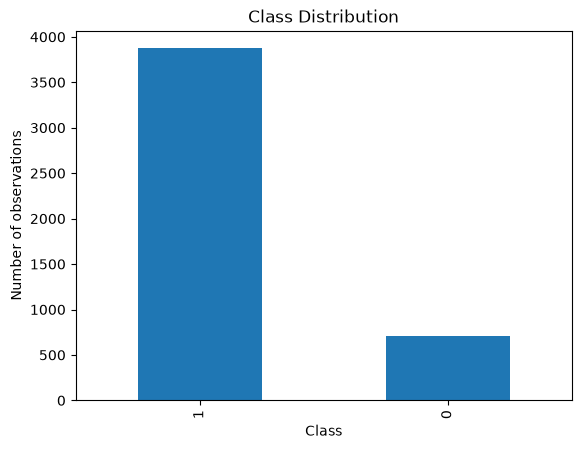

In [ ]:
##Checking the class distribution and imbalance in the training data

print("Class distribution:")
print(train['output'].value_counts())

print("\nClass percentages:")
print(train['output'].value_counts(normalize=True) * 100)

train['output'].value_counts().plot(
    kind='bar',
    title='Class Distribution'
)

plt.xlabel("Class")
plt.ylabel("Number of observations")
plt.show()

In [ ]:
# Separate features and target of the training data
X = train.drop(columns=['output'])
y = train['output']

# Stratified train-validation split
X_train, X_val, y_train, y_val = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training observations:", X_train.shape)
print("Validation observations:", X_val.shape)

Training observations: (3667, 669)
Validation observations: (917, 669)


In [ ]:
# Identify numerical and categorical columns
from sklearn.compose import ColumnTransformer

numeric_features = X.select_dtypes(
    include=['int64', 'float64']
).columns.tolist()

categorical_features = X.select_dtypes(
    include=['object', 'category', 'bool']
).columns.tolist()


# Numeric preprocessing
numeric_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])


# Categorical preprocessing
categorical_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

# Combine preprocessing
preprocessor = ColumnTransformer([
    ('num', numeric_transformer, numeric_features),
    ('cat', categorical_transformer, categorical_features)
])

/var/folders/c3/1xdc_j3d5gnbhhnvrtwj5c540000gn/T/ipykernel_51303/3195068650.py:8: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = X.select_dtypes(


In [ ]:
import numpy as np
import pandas as pd
import shap

from xgboost import XGBClassifier
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.metrics import roc_auc_score

In [ ]:
#XGBoost Classifier

xgb_model = Pipeline([
    ('preprocessor', clone(preprocessor)),
    ('classifier', XGBClassifier(
        n_estimators=400,
        max_depth=3,
        learning_rate=0.03,
        subsample=0.8,
        colsample_bytree=0.8,
        reg_lambda=5,
        objective='binary:logistic',
        eval_metric='auc',
        tree_method='hist',
        random_state=42,
        n_jobs=2
    ))
])

xgb_model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](669,)","['x1','x2','x3',...,'subject','phase','state']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,669
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns 

In [ ]:
#Calculate the SHAP values for the XGBoost model

processor = xgb_model.named_steps['preprocessor']
classifier = xgb_model.named_steps['classifier']

X_train_processed = processor.transform(X_train)
X_val_processed = processor.transform(X_val)

explainer = shap.TreeExplainer(classifier)
shap_values = explainer.shap_values(X_train_processed)
shap_importance = np.abs(shap_values).mean(axis=0)

In [ ]:
#Select the top 50 features based on SHAP importance

top_features = np.argsort(shap_importance)[-50:]

X_train_shap = X_train_processed[:, top_features]
X_val_shap = X_val_processed[:, top_features]

print("Selected Features:", len(top_features))

Selected Features: 50


In [ ]:
#Train a new OptimizedXGBoost model using the selected features

shap_xgb = XGBClassifier(
    n_estimators=500,
    max_depth=3,
    learning_rate=0.025,
    subsample=0.85,
    colsample_bytree=0.85,
    min_child_weight=3,
    reg_alpha=1,
    reg_lambda=10,
    objective='binary:logistic',
    eval_metric='auc',
    tree_method='hist',
    random_state=42,
    n_jobs=2
)

shap_xgb.fit(X_train_shap, y_train)

,"base_score base_score: float | typing.List[float] | NoneThe initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.List[xgboost.callback.TrainingCallback] | NoneList of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: float | NoneSubsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: float | NoneSubsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: float | NoneSubsample ratio of columns when constructing each tree.,0.85
,"device device: str | None.. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: int | None.. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: str | typing.List[str | typing.Callable] | typing.Callable | None.. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",'auc'
,feature_types feature_types: typing.Sequence[str] | None.. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


In [ ]:
#Evaluate the ROC-AUC of the baseline XGBoost model and the SHAP-based XGBoost model on the validation set

baseline_preds = xgb_model.predict_proba(X_val)[:, 1]

shap_preds = shap_xgb.predict_proba(X_val_shap)[:, 1]

print("Baseline ROC-AUC:",
      roc_auc_score(y_val, baseline_preds))

print("SHAP XGBoost ROC-AUC:",
      roc_auc_score(y_val, shap_preds))

Baseline ROC-AUC: 0.8550749659245797
SHAP XGBoost ROC-AUC: 0.8469150386188097


In [ ]:
#Code generated with the help of AI

# Fit preprocessing on all labeled data
final_processor = clone(preprocessor)

X_full = final_processor.fit_transform(X)

test_1 = test.reindex(columns=X.columns)
X_test = final_processor.transform(test_1)

# Recalculate SHAP feature importance using full training data
ranking_model = clone(classifier)
ranking_model.fit(X_full, y)

final_explainer = shap.TreeExplainer(ranking_model)
final_shap = final_explainer.shap_values(X_full)

final_importance = np.abs(final_shap).mean(axis=0)
final_top_features = np.argsort(final_importance)[-50:]

# Retrain final model
final_model = clone(shap_xgb)

final_model.fit(
    X_full[:, final_top_features],
    y
)

test_probs = final_model.predict_proba(
    X_test[:, final_top_features]
)[:, 1]

In [ ]:
#Create the submission file for the XGBoost model with SHAP feature selection

sample_solution = pd.read_csv(
    "sample_solution.csv"
)

submission = sample_solution.copy()

submission["output"] = test_probs

submission.to_csv(
    "xgboost_shap_submission.csv",
    index=False
)

print(submission.head())
print("Submission shape:", submission.shape)

   id    output
0   0  0.910014
1   1  0.917869
2   2  0.841883
3   3  0.781148
4   4  0.901500
Submission shape: (1732, 2)
